dataset - https://www.kaggle.com/datasets/easonlll/hmdb51?resource=download.

Boli vybrate dve katerogoorie - drink a eat. Je ich tam ovela viac. Jednoduchsie kategorie lahsi overit.

pre system Ubuntu otvorte terminal(da sa aj vo VS code). Otvorit direktoriu a po tom python3 -m venv venv(vyvtori virtualne prostedie kde mozete naistnolovat baliky)
dalej
source venv/bin/activate
pre deaktivacou - deactivate 
dalej
pip install -U ipykernel
Hore vrpavo vybrat vytvrony VENV ako spustaci kernel 
pip install torch torchvision opencv-python scikit-learn pandas matplotlib

In [1]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from torch.utils.data import Dataset, DataLoader

ROOT = Path("HMDB51")
CLASSES = ["eat", "drink"]
N_FRAMES = 16   # кадров на клип
SIZE = 224      # вход ResNet
SEED = 0

In [2]:
def build_index(root=ROOT, classes=CLASSES, seed=SEED):
    rows = []
    for label, cls in enumerate(classes):
        for p in sorted((root / cls).iterdir()):
            if not p.is_dir():
                continue
            # имя клипа: <источник>_<класс>_<6 полей метаданных>
            source = p.name.rsplit("_", 6)[0].removesuffix(f"_{cls}")
            rows.append((str(p), cls, label, source))
    df = pd.DataFrame(rows, columns=["path", "cls", "label", "source"])

    df["split"] = "train"
    gss = GroupShuffleSplit(n_splits=1, test_size=0.3, random_state=seed)
    trainval, test = next(gss.split(df, groups=df.source))
    df.loc[df.index[test], "split"] = "test"

    tv = df.iloc[trainval]
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed)
    _, val = next(gss.split(tv, groups=tv.source))
    df.loc[tv.index[val], "split"] = "val"
    return df

df = build_index()
print(pd.crosstab(df.split, df.cls))
assert df.groupby("source").split.nunique().max() == 1  # нет утечки
df.to_csv("index.csv", index=False)

cls    drink  eat
split            
test      46   34
train     96   65
val       22    9


In [6]:
from torchvision.models import ResNet18_Weights
print(ResNet18_Weights.IMAGENET1K_V1.transforms())

ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BILINEAR
)


In [3]:
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def read_frames(path, n=N_FRAMES, size=SIZE):
    files = sorted(Path(path).glob("*.jpg"), key=lambda f: int(f.stem))
    if not files:
        raise RuntimeError(f"no frames in {path}")
    idx = np.linspace(0, len(files) - 1, n).round().astype(int)
    frames = [cv2.imread(str(files[i])) for i in idx]
    return np.stack([cv2.resize(cv2.cvtColor(f, cv2.COLOR_BGR2RGB), (size, size)) for f in frames])

def preprocess(frames):
    x = torch.from_numpy(frames).permute(0, 3, 1, 2).float() / 255
    return (x - MEAN) / STD

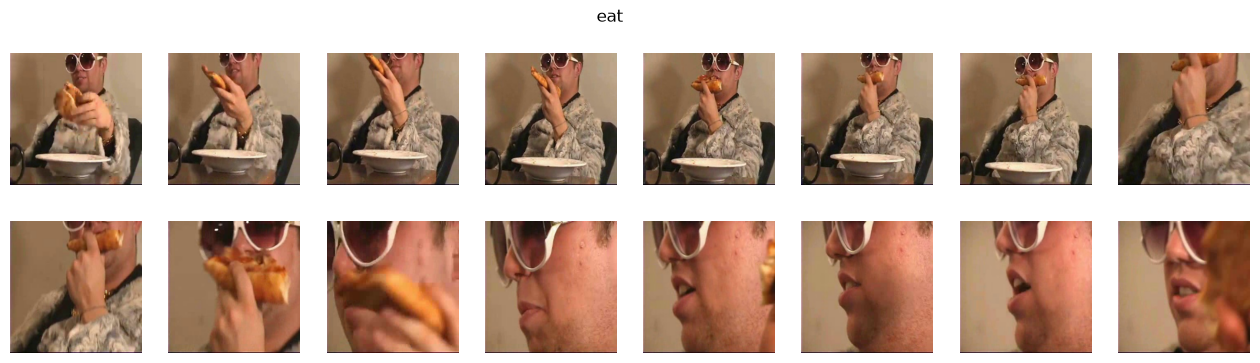

In [4]:
row = df.iloc[0]
frames = read_frames(row.path)
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for ax, f in zip(axes.flat, frames):
    ax.imshow(f)
    ax.axis("off")
fig.suptitle(row.cls)
plt.show()

In [5]:
class ClipDataset(Dataset):
    def __init__(self, df, split):
        self.df = df[df.split == split].reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        row = self.df.iloc[i]
        return preprocess(read_frames(row.path)), int(row.label)

x, y = next(iter(DataLoader(ClipDataset(df, "train"), batch_size=4, shuffle=True)))
print(x.shape, y)  # ожидаем (4, 16, 3, 224, 224)

torch.Size([4, 16, 3, 224, 224]) tensor([1, 1, 0, 1])
